# Comparing methods on one continual setting

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eleninisioti/continual_neuroevolution/blob/main/notebooks/compare_methods.ipynb)

This notebook compares the seven methods of the paper on one setting, **CartPole with observation offsets**, using every metric the paper reports:

1. the **training curves**;
2. the **stability-plasticity trade-off** (learning accuracy LA against forgetting F, Figure 2), and the cumulative return (Cum.) and zero-shot transfer (ZT);
3. the **symptoms of plasticity loss**: dormant units and weight growth;
4. the **diversity of the population** for the population-based methods.

The setting: ten observation offsets drawn from $\mathcal N(0, I)$ (the first is zero), visited in order and then a second time, so a run sees 20 tasks. Every method gets the same environment steps per task and is never told when the task switches. There are 10 trials per method.

| | |
|---|---|
| **NE** | GA, ES |
| **RL** | PPO, TRAC-PPO, ReDo-PPO, C-CHAIN, PBT-PPO |

For the population methods (GA, ES, PBT-PPO) we evaluate the **centroid**, the mean of the population's weights; for the others the single network.

Everything below is computed from the agents saved at the end of each task and from the training records. CartPole is re-implemented in numpy, so the notebook needs neither JAX nor the training code. The data file `data/compare/cartpole_noise.npz` was made from the run directories with `load_run` below; point `RUNS` at your own runs (`runs/gymnax/continual/` after `scripts/train/run.sh`) to use them instead.

In [1]:
import json, os, pathlib, subprocess

# On Colab (or anywhere without the repository) fetch it for the data files.
if not pathlib.Path('data/compare').exists():
    if not pathlib.Path('continual_neuroevolution').exists():
        subprocess.run(['git', 'clone', '--depth', '1',
                        'https://github.com/eleninisioti/continual_neuroevolution'], check=True)
    os.chdir('continual_neuroevolution/notebooks')

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

METHODS = ['ga', 'es', 'ppo', 'trac', 'redo', 'cchain', 'pbt']
NAMES = {'ga': 'GA', 'es': 'ES', 'ppo': 'PPO', 'trac': 'TRAC-PPO', 'redo': 'ReDo-PPO',
         'cchain': 'C-CHAIN', 'pbt': 'PBT-PPO'}
COLOURS = {'ga': '#4CBB47', 'es': '#F0C33C', 'ppo': '#E8504F', 'trac': '#F08C4B',
           'redo': '#8B4A2B', 'cchain': '#7B5EA7', 'pbt': '#B5306B'}
NE = {'ga', 'es'}
POPULATION = ['ga', 'es', 'pbt']

## Loading runs

A run directory written by `scripts/train/run.sh` holds `checkpoints.npz` (the agent at the end of every task and the task offsets), `training_metrics.json` (one record per evaluation) and `results.json` (the configuration). The three families log their return under different names; `load_run` reduces any of them to the same few arrays.

In [2]:
CURVE_POINTS = 400        # training curves are binned to this many points
DIVERSITY_POINTS = 100    # diversity is logged more sparsely, so coarser bins
DIVERSITY = {             # the paper's diversity measures -> record column(s), first present wins
    'genomic': ('bd_genomic_diversity',),
    'behavioural': ('bd_behavioural_diversity', 'bd_probe_disagreement'),
    'fitness_sd': ('bd_fitness_std',),
}


def binned(x, y, num_tasks, points=CURVE_POINTS):
    # Mean of y in `points` equal bins of x in [0, num_tasks].
    x, y = np.asarray(x, float), np.asarray(y, float)
    idx = np.clip(np.digitize(x, np.linspace(0, num_tasks, points + 1)) - 1, 0, points - 1)
    out = np.full(points, np.nan)
    for b in np.unique(idx):
        v = y[(idx == b) & np.isfinite(y)]
        if v.size:
            out[b] = v.mean()
    return out


def load_run(trial_dir):
    trial_dir = pathlib.Path(trial_dir)
    ckpt = np.load(trial_dir / 'checkpoints.npz')
    records = json.loads((trial_dir / 'training_metrics.json').read_text())
    result = json.loads((trial_dir / 'results.json').read_text())
    cfg = result.get('config') or result
    agent = ckpt['centroid'] if 'centroid' in ckpt.files else ckpt['final']
    T = len(agent)
    first = records[0]
    if 'timestep' in first:                  # PPO, TRAC-PPO, ReDo-PPO, C-CHAIN
        x = np.array([r['timestep'] for r in records], float) / cfg['num_timesteps'] * T
        y = [r['mean_reward'] for r in records]
    elif 'centroid_task0' in first:          # PBT-PPO scores its centroid on every task
        x = np.array([r['generation'] for r in records], float) / cfg['task_interval']
        y = [r[f"centroid_task{r['task']}"] for r in records]
    else:                                    # GA, ES
        x = np.array([r['generation'] for r in records], float) / cfg['task_interval']
        y = [r['centroid_fitness'] for r in records]
    diversity = {}
    for name, cols in DIVERSITY.items():
        col = next((c for c in cols if c in first), None)
        if col is not None:
            diversity[name] = binned(x, [r.get(col, np.nan) for r in records], T, DIVERSITY_POINTS)
    return dict(centroid=agent.astype(np.float32), offsets=ckpt['noise_vectors'][:T].astype(np.float32),
                curve=binned(x, y, T), diversity=diversity)


RUNS = None   # e.g. pathlib.Path('../runs/gymnax/continual'), with <method>/CartPole_v1_sigma1.0/trial_*/
ARM = {'es': 'nes'}   # directory name of a method, where it differs (the paper's ES runs are under nes/)

if RUNS is None:
    blob = np.load('data/compare/cartpole_noise.npz')
    data = {m: {k.split('/', 1)[1]: blob[k] for k in blob.files if k.startswith(m + '/')} for m in METHODS}
else:
    data = {}
    for m in METHODS:
        runs = [load_run(t) for t in sorted((RUNS / ARM.get(m, m) / 'CartPole_v1_sigma1.0').glob('trial_*'))]
        data[m] = {k: np.stack([r[k] for r in runs]) for k in ('centroid', 'offsets', 'curve')}
        for k in runs[0]['diversity']:
            data[m][f'diversity_{k}'] = np.stack([r['diversity'][k] for r in runs])

for m in METHODS:
    print(f"{NAMES[m]:9s} {data[m]['centroid'].shape[0]} trials, {data[m]['centroid'].shape[1]} tasks, "
          f"{data[m]['centroid'].shape[2]} weights")

GA        10 trials, 20 tasks, 386 weights
ES        10 trials, 20 tasks, 386 weights
PPO       10 trials, 20 tasks, 386 weights
TRAC-PPO  10 trials, 20 tasks, 386 weights
ReDo-PPO  10 trials, 20 tasks, 386 weights
C-CHAIN   10 trials, 20 tasks, 386 weights
PBT-PPO   10 trials, 20 tasks, 386 weights


Statistics follow the paper: the mean over trials with a 95% percentile-bootstrap interval, and one-sided Mann-Whitney U tests with Holm's correction.

In [3]:
def bootstrap_ci(values, n_boot=2000, seed=0):
    v = np.asarray(values, float)
    v = v[np.isfinite(v)]
    means = np.random.default_rng(seed).choice(v, (n_boot, v.size)).mean(1)
    return v.mean(), *np.percentile(means, [2.5, 97.5])


def bootstrap_band(curves, n_boot=1000, seed=0):
    # Mean curve over trials (rows) and its 95% band.
    c = np.asarray(curves, float)
    idx = np.random.default_rng(seed).integers(0, len(c), (n_boot, len(c)))
    means = np.nanmean(c[idx], 1)
    return np.nanmean(c, 0), np.nanpercentile(means, 2.5, 0), np.nanpercentile(means, 97.5, 0)


def holm(ps):
    order, adj, running = np.argsort(ps), np.empty(len(ps)), 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (len(ps) - rank) * ps[i]))
        adj[i] = running
    return adj

## 1. Training curves

The return of the evaluated agent on the task it is currently trained on, over the whole run. The dashed lines are the task switches.

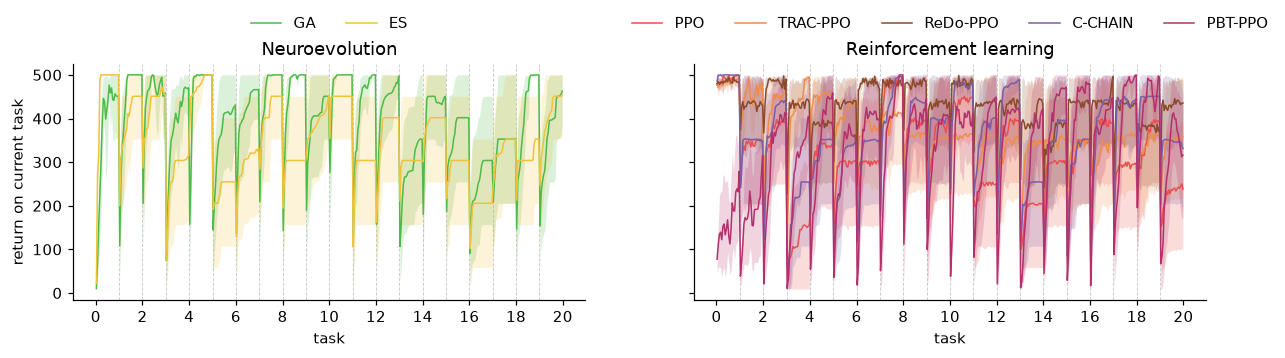

In [4]:
T = data['ga']['centroid'].shape[1]
x = (np.arange(CURVE_POINTS) + 0.5) / CURVE_POINTS * T
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, group, title in ((axes[0], ['ga', 'es'], 'Neuroevolution'),
                         (axes[1], ['ppo', 'trac', 'redo', 'cchain', 'pbt'], 'Reinforcement learning')):
    for m in group:
        mean, lo, hi = bootstrap_band(data[m]['curve'])
        ax.plot(x, mean, color=COLOURS[m], lw=1, label=NAMES[m])
        ax.fill_between(x, lo, hi, color=COLOURS[m], alpha=0.2, lw=0)
    for t in range(1, T):
        ax.axvline(t, color='0.8', lw=0.6, ls='--', zorder=0)
    ax.set_title(title); ax.set_xlabel('task'); ax.set_xticks(range(0, T + 1, 2))
    ax.legend(frameon=False, ncol=len(group), loc='lower center', bbox_to_anchor=(0.5, 1.08))
axes[0].set_ylabel('return on current task')
plt.tight_layout(); plt.show()

## 2. Stability and plasticity

### The reward matrix

Every metric of stability and plasticity is read from one matrix per run: $R_{ij}$ is the return of the agent saved at the end of task $j$ when it is evaluated on task $i$ (10 fresh episodes, greedy actions). We compute it here with a numpy CartPole.

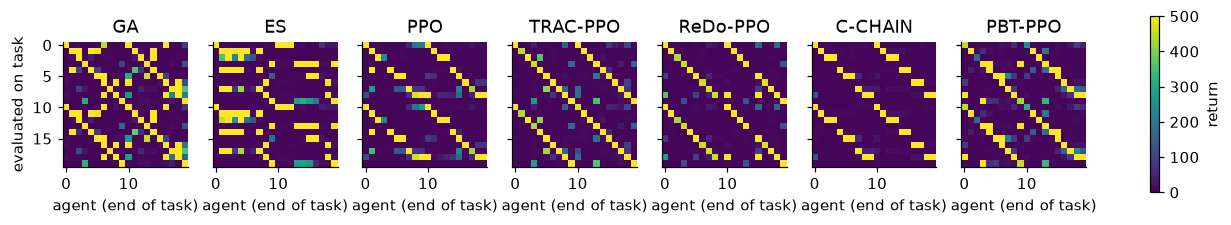

In [5]:
# CartPole-v1 as gymnax implements it, vectorised over policies and episodes.
G, M_CART, M_POLE, LENGTH, FORCE, TAU = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
M_TOT, PML = M_CART + M_POLE, M_POLE * LENGTH
THETA_MAX, X_MAX, MAX_STEPS = 12 * 2 * np.pi / 360, 2.4, 500

# The policy is 4 -> 16 -> 16 -> 2 with ReLU, greedy; the flat weight vector lists
# its tensors in this order (flax's ravel_pytree: per layer, bias first).
SHAPES = [(16,), (4, 16), (16,), (16, 16), (2,), (16, 2)]
SIZES = [int(np.prod(s)) for s in SHAPES]


def unflatten(theta):
    out, i = [], 0
    for s, n in zip(SHAPES, SIZES):
        out.append(theta[..., i:i + n].reshape(theta.shape[:-1] + s))
        i += n
    return out


def hidden(theta, obs):
    b0, W0, b1, W1, b2, W2 = unflatten(theta)
    h1 = np.maximum(obs @ W0 + b0, 0)
    return h1, np.maximum(h1 @ W1 + b1, 0)


def act(thetas, obs):
    # Greedy actions of P policies (P, 386) on observations (P, E, 4).
    b0, W0, b1, W1, b2, W2 = unflatten(thetas)
    h = np.maximum(np.einsum('pei,pij->pej', obs, W0) + b0[:, None], 0)
    h = np.maximum(np.einsum('pei,pij->pej', h, W1) + b1[:, None], 0)
    return np.argmax(np.einsum('pei,pij->pej', h, W2) + b2[:, None], -1)


def step(s, a):
    x, xd, th, thd = np.moveaxis(s, -1, 0)
    f = np.where(a == 1, FORCE, -FORCE)
    c, si = np.cos(th), np.sin(th)
    tmp = (f + PML * thd ** 2 * si) / M_TOT
    tha = (G * si - c * tmp) / (LENGTH * (4 / 3 - M_POLE * c ** 2 / M_TOT))
    xa = tmp - PML * tha * c / M_TOT
    return np.stack([x + TAU * xd, xd + TAU * xa, th + TAU * thd, thd + TAU * tha], -1)


def failed(s):
    return (np.abs(s[..., 0]) > X_MAX) | (np.abs(s[..., 2]) > THETA_MAX)


def returns(thetas, offset, episodes=10, seed=0):
    # Mean return of each policy when it sees obs + offset.
    thetas = np.atleast_2d(thetas)
    rng = np.random.default_rng(seed)
    s = rng.uniform(-0.05, 0.05, size=(len(thetas), episodes, 4))
    ret, alive = np.zeros(s.shape[:2]), np.ones(s.shape[:2], bool)
    for _ in range(MAX_STEPS):
        s = step(s, act(thetas, s + offset))
        ret += alive
        alive &= ~failed(s)
        if not alive.any():
            break
    return ret.mean(-1)


def reward_matrix(centroids, offsets, episodes=10, seed=0):
    # R[i, j]: agent j on task i.
    return np.stack([returns(centroids, offsets[i], episodes, seed + i) for i in range(len(offsets))])


R = {m: np.stack([reward_matrix(c, o) for c, o in zip(data[m]['centroid'], data[m]['offsets'])])
     for m in METHODS}

fig, axes = plt.subplots(1, len(METHODS), figsize=(15, 2.6), sharey=True)
for ax, m in zip(axes, METHODS):
    im = ax.imshow(R[m][0], vmin=0, vmax=500, cmap='viridis')
    ax.set_title(NAMES[m]); ax.set_xlabel('agent (end of task)')
axes[0].set_ylabel('evaluated on task')
fig.colorbar(im, ax=axes, shrink=0.8, label='return'); plt.show()

### The metrics

* **Learning accuracy** (LA, plasticity) $= \frac1T\sum_i R_{ii}$: how well each task is learnt by the end of its own training.
* **Forgetting** (F, stability) $= \frac{1}{T-1}\sum_{i<T} (R_{ii} - R_{iT})$: the return lost on each task between the end of training on it and the end of the run.
* **Zero-shot transfer** (ZT) $= \frac{1}{T-1}\sum_{i<T} R_{i+1,i}$: the return on the next task at the moment of the switch, before any training on it.
* **Cumulative return** (Cum.): the mean of the training curve above, which also rewards recovering quickly after a switch.

To compare settings, the paper rescales LA and F so that 0 is the untrained network (a return of 10 on CartPole) and 1 the highest mean LA of any method in the setting. LA − F is then the share of a task's return that is kept.

In [6]:
FLOOR = 10.0
raw = {m: dict(LA=np.array([np.mean(np.diag(r)) for r in R[m]]),
               F=np.array([np.mean(np.diag(r)[:-1] - r[:-1, -1]) for r in R[m]]),
               ZT=np.array([np.mean([r[i + 1, i] for i in range(T - 1)]) for r in R[m]]),
               Cum=np.nanmean(data[m]['curve'], 1)) for m in METHODS}
BEST = max(raw[m]['LA'].mean() for m in METHODS)
scaled = {m: dict(LA=(v['LA'] - FLOOR) / (BEST - FLOOR), F=v['F'] / (BEST - FLOOR)) for m, v in raw.items()}

# The values the paper reports for this setting, for comparison (evaluation episodes differ).
paper = json.loads(pathlib.Path('data/compare/paper_values.json').read_text())
print(f"{'':10s}{'LA':>8s}{'(paper)':>9s}{'F':>8s}{'(paper)':>9s}{'Cum.':>8s}{'(paper)':>9s}{'ZT':>8s}")
for m in METHODS:
    print(f"{NAMES[m]:10s}{raw[m]['LA'].mean():8.0f}{np.mean(paper[m]['la']):9.0f}{raw[m]['F'].mean():8.0f}"
          f"{np.mean(paper[m]['F']):9.0f}{raw[m]['Cum'].mean():8.0f}{np.mean(paper[m]['cum']):9.0f}{raw[m]['ZT'].mean():8.0f}")

                LA  (paper)       F  (paper)    Cum.  (paper)      ZT
GA             453      453     343      343     398      398      60
ES             377      378     230      232     349      349      81
PPO            343      343     289      290     321      320      45
TRAC-PPO       395      396     340      341     370      370      37
ReDo-PPO       443      443     394      395     431      430      41
C-CHAIN        398      398     322      321     361      361      49
PBT-PPO        420      420     350      351     326      326      41


### The trade-off (Figure 2)

Each method is a point: rescaled LA against rescaled F, with 95% bootstrap intervals over trials. Better is up and to the right (the F axis is inverted). The grey lines are equal LA − F, and the ring marks the method with the highest LA − F.

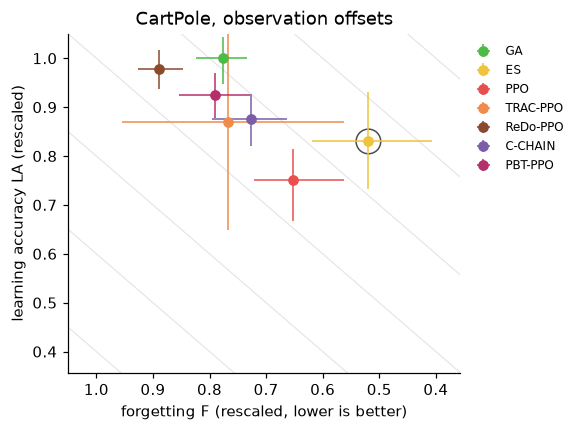

LA - F: ES 0.31, GA 0.22, C-CHAIN 0.15, PBT-PPO 0.13, TRAC-PPO 0.10, PPO 0.10, ReDo-PPO 0.09


In [7]:
fig, ax = plt.subplots(figsize=(4.6, 4))
keep = {m: scaled[m]['LA'].mean() - scaled[m]['F'].mean() for m in METHODS}
for level in np.arange(-1, 1.01, 0.2):
    f = np.linspace(-0.2, 1.2, 2)
    ax.plot(f, f + level, color='0.9', lw=0.8, zorder=0)
for m in METHODS:
    la, la_lo, la_hi = bootstrap_ci(scaled[m]['LA'])
    f, f_lo, f_hi = bootstrap_ci(scaled[m]['F'])
    ax.errorbar(f, la, xerr=[[f - f_lo], [f_hi - f]], yerr=[[la - la_lo], [la_hi - la]],
                fmt='o', color=COLOURS[m], ms=6, lw=1, capsize=0, label=NAMES[m], zorder=3)
best = max(keep, key=keep.get)
ax.scatter(scaled[best]['F'].mean(), scaled[best]['LA'].mean(), s=260, facecolor='none',
           edgecolor='0.3', lw=1, zorder=2)
lows = [bootstrap_ci(scaled[m][k])[1] for m in METHODS for k in ('LA', 'F')]
lo = max(min(lows) - 0.05, -0.1)
ax.set_xlim(1.05, lo); ax.set_ylim(lo, 1.05)
ax.set_xlabel('forgetting F (rescaled, lower is better)'); ax.set_ylabel('learning accuracy LA (rescaled)')
ax.legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
ax.set_title('CartPole, observation offsets')
plt.show()
print('LA - F:', ', '.join(f'{NAMES[m]} {keep[m]:.2f}' for m in sorted(keep, key=keep.get, reverse=True)))

A method has the best trade-off when it has the highest LA − F *and* keeps significantly more than every method of the other family. The test is a one-sided Mann-Whitney U over trials, Holm-corrected over the comparisons.

In [8]:
def better_than_other_family(values):
    # {method: (Holm p-values against every method of the other family, all < 0.05?)}
    out = {}
    for m in METHODS:
        rivals = [r for r in METHODS if (r in NE) != (m in NE)]
        ps = holm(np.array([mannwhitneyu(values[m], values[r], alternative='greater').pvalue for r in rivals]))
        out[m] = (dict(zip(rivals, ps.round(4))), bool((ps < 0.05).all()))
    return out


la_minus_f = {m: scaled[m]['LA'] - scaled[m]['F'] for m in METHODS}
for m, (ps, wins) in better_than_other_family(la_minus_f).items():
    print(f"{NAMES[m]:9s} LA - F = {la_minus_f[m].mean():.2f}  better than every {'RL' if m in NE else 'NE'} method: {wins}")

GA        LA - F = 0.22  better than every RL method: False
ES        LA - F = 0.31  better than every RL method: True
PPO       LA - F = 0.10  better than every NE method: False
TRAC-PPO  LA - F = 0.10  better than every NE method: False
ReDo-PPO  LA - F = 0.09  better than every NE method: False
C-CHAIN   LA - F = 0.15  better than every NE method: False
PBT-PPO   LA - F = 0.13  better than every NE method: False


### Cumulative return and zero-shot transfer

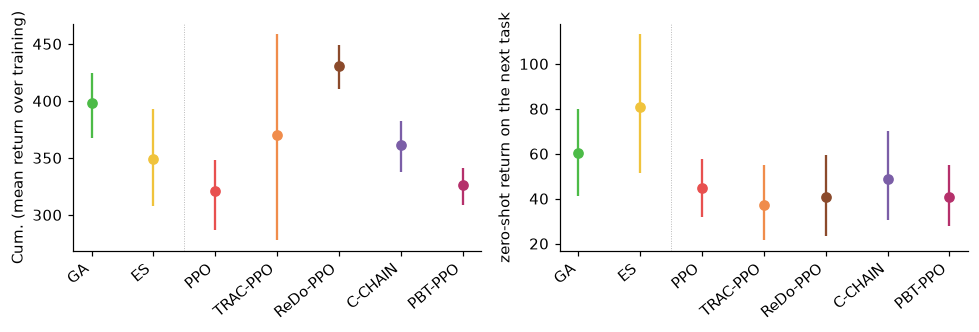

* = better than every method of the other family (one-sided Mann-Whitney U, Holm, p < 0.05)


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, key, label in ((axes[0], 'Cum', 'Cum. (mean return over training)'),
                       (axes[1], 'ZT', 'zero-shot return on the next task')):
    marks = better_than_other_family({m: raw[m][key] for m in METHODS})
    for i, m in enumerate(METHODS):
        mean, lo, hi = bootstrap_ci(raw[m][key])
        ax.errorbar(i, mean, yerr=[[mean - lo], [hi - mean]], fmt='o', color=COLOURS[m], ms=6, capsize=0)
        if marks[m][1]:
            ax.text(i, hi, '*', ha='center', va='bottom', fontsize=12)
    ax.set_xticks(range(len(METHODS))); ax.set_xticklabels([NAMES[m] for m in METHODS], rotation=40, ha='right')
    ax.axvline(1.5, color='0.7', lw=0.6, ls=':')
    ax.set_ylabel(label)
plt.tight_layout(); plt.show()
print('* = better than every method of the other family (one-sided Mann-Whitney U, Holm, p < 0.05)')

## 3. Symptoms of plasticity loss

**Dormant units.** A hidden unit is dormant when its mean absolute activation over a batch of states is at most $\tau = 0.025$ of its layer's mean (ReDo's criterion). The states are one fixed batch, drawn by a uniform-random policy and shared equally across all tasks' offsets, so that a unit is compared with itself on the same states at every checkpoint.

**Weight growth.** The root mean square of the weights at the end of each task, relative to the first.

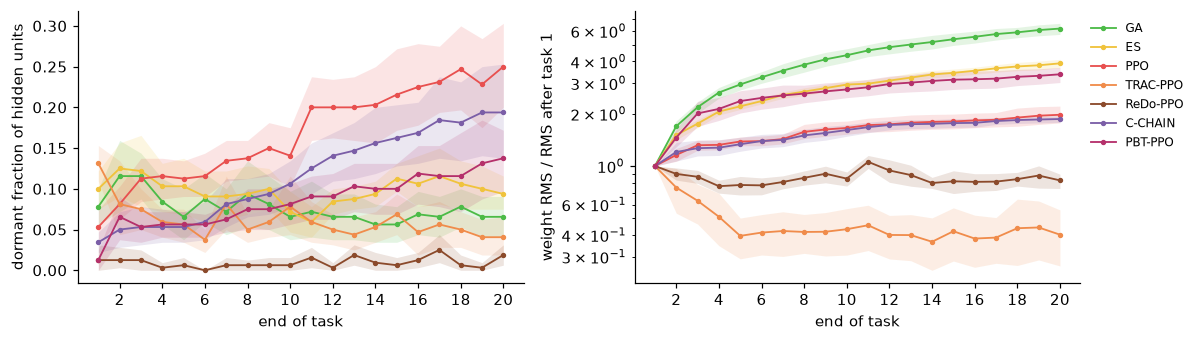

In [10]:
def random_policy_states(n=512, seed=0):
    rng = np.random.default_rng(seed)
    out, s = [], rng.uniform(-0.05, 0.05, 4)
    while len(out) < n:
        out.append(s)
        s = step(s, rng.integers(2))
        if failed(s):
            s = rng.uniform(-0.05, 0.05, 4)
    return np.array(out)


def pooled_probe(offsets, n=512, seed=0):
    # An equal share of n random-policy states for every distinct task.
    base = random_policy_states(n, seed)
    tasks = np.unique(np.round(offsets, 6), axis=0)
    pick = base[np.linspace(0, n - 1, n // len(tasks)).astype(int)]
    return np.concatenate([pick + o for o in tasks])


def dormant_fraction(theta, probe, tau=0.025):
    frac = []
    for h in hidden(theta, probe):
        score = np.abs(h).mean(0)
        frac.append(score / (score.mean() + 1e-9) <= tau)
    return np.concatenate(frac).mean()


dormant = {m: np.array([[dormant_fraction(c, pooled_probe(o)) for c in cs]
                        for cs, o in zip(data[m]['centroid'], data[m]['offsets'])]) for m in METHODS}
rms = {m: np.sqrt((data[m]['centroid'] ** 2).mean(-1)) for m in METHODS}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
tasks = np.arange(1, T + 1)
for m in METHODS:
    for ax, values in ((axes[0], dormant[m]), (axes[1], rms[m] / rms[m][:, :1])):
        mean, lo, hi = bootstrap_band(values)
        ax.plot(tasks, mean, color=COLOURS[m], lw=1.2, marker='o', ms=2.5, label=NAMES[m])
        ax.fill_between(tasks, lo, hi, color=COLOURS[m], alpha=0.15, lw=0)
axes[0].set_ylabel('dormant fraction of hidden units')
axes[1].set_ylabel('weight RMS / RMS after task 1'); axes[1].set_yscale('log')
for ax in axes:
    ax.set_xlabel('end of task')
    ax.set_xticks(range(2, T + 1, 2))
axes[1].legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

## 4. Population diversity

For the methods that keep a population, the training records log three measures of how spread out it is:

* **genomic diversity**: the mean pairwise distance between members' weights, divided by $\sqrt{2P}$ ($P$ = 386 weights), so it reads as a distance per weight;
* **behavioural diversity**: how often two members choose different actions on the same probe states;
* **fitness s.d.**: the spread of the members' returns.

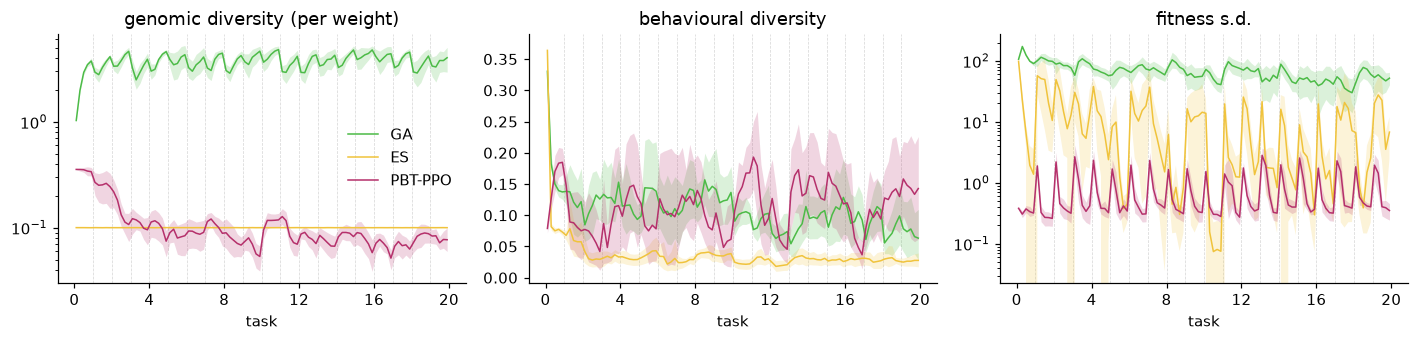

In [11]:
P = data['ga']['centroid'].shape[-1]
panels = [('genomic', 'genomic diversity (per weight)', True),
          ('behavioural', 'behavioural diversity', False),
          ('fitness_sd', 'fitness s.d.', True)]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (key, label, log) in zip(axes, panels):
    for m in POPULATION:
        values = data[m][f'diversity_{key}'] / (np.sqrt(2 * P) if key == 'genomic' else 1)
        mean, lo, hi = bootstrap_band(values)
        xd = (np.arange(values.shape[1]) + 0.5) / values.shape[1] * T
        ax.plot(xd, mean, color=COLOURS[m], lw=1, label=NAMES[m])
        ax.fill_between(xd, lo, hi, color=COLOURS[m], alpha=0.2, lw=0)
    for t in range(1, T):
        ax.axvline(t, color='0.85', lw=0.5, ls='--', zorder=0)
    ax.set_xticks(range(0, T + 1, 4))
    ax.set_title(label); ax.set_xlabel('task')
    if log:
        ax.set_yscale('log')
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()